# Дисперсионный анализ (ANOVA / MANOVA) — лабораторное задание

Лабораторная про два статистических метода проверки гипотез о различии групп

Дисперсионный анализ (ANOVA) — это метод проверки гипотезы о равенстве средних в нескольких группах. Он раскладывает общий разброс данных на межгрупповой (сигнал) и внутригрупповой (шум) и сравнивает их через F-статистику. Если сигнал значительно больше шума — группы различаются. В лабораторной мы использовали двухфакторный ANOVA для проверки влияния грунта, вида, района и условий на вес иглокожих, а MANOVA — для проверки различий между группами университетов по трём рейтингам одновременно, с учётом их корреляций

ANOVA (Analysis of Variance, дисперсионный анализ) — когда у нас одна числовая зависимая переменная (отклик) и один или несколько категориальных факторов. Проверяем: различаются ли средние значения отклика между группами, заданными факторами.

MANOVA (Multivariate ANOVA) — то же самое, но несколько числовых зависимых переменных сразу. Проверяем: различаются ли векторы средних (сразу по всем откликам) между группами.

**Задание 1.** Двухфакторный ANOVA по `DA.csv` (ВесИглокожих):
`weight ~ priming * view`, `weight ~ priming * region`, `weight ~ priming * conditions`.

**Задание 2.** MANOVA по `university2.csv` (данные переделаны!):
рейтинги `Yslov_educ + Yslov_job + Yslov_science` в зависимости от группы университета
(группа строится по месту в рейтинге `mesto2016`: топ-10 / 11–30 / 31–60 / 61+ / нет данных).

> **Почему не `University ~ ratings`?** Потому что `University` — это идентификатор (83 уровня на 83 наблюдения → residual df = 0 → MANOVA вырождается). Классическая MANOVA: отклики = рейтинги, фактор = группа.

In [2]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.formula.api as smf
from statsmodels.stats.anova import anova_lm
from statsmodels.multivariate.manova import MANOVA

plt.rcParams["figure.figsize"] = (10, 6)
sns.set_style("whitegrid")

OUT_DIR = "output"
os.makedirs(OUT_DIR, exist_ok=True)

def find_col(df, candidates):
    for c in candidates:
        if c in df.columns:
            return c
    raise KeyError(f"Не найдена колонка: {candidates}. Есть: {list(df.columns)}")

Короткая идея
ANOVA — это статистический тест, который проверяет гипотезу:

H₀: средние значения отклика во всех группах равны (фактор не влияет).
H₁: хотя бы одно среднее отличается.

Например: «средний вес иглокожих одинаков на всех типах грунта» — это H₀. Если данные говорят, что нет, — отвергаем H₀ и говорим «грунт влияет на вес».

Почему «анализ дисперсии», если сравниваем средние
Это ключевой момент, который часто спрашивают. Дело в том, что ANOVA не сравнивает средние напрямую. Она раскладывает общую вариабельность данных на две части:

Межгрупповая дисперсия (between-group, SS_between) — насколько средние групп отличаются от общего среднего. Если фактор реально влияет, группы «разъезжаются» → эта часть большая.

Внутригрупповая дисперсия (within-group, residual, SS_within) — разброс значений внутри каждой группы вокруг её среднего. Это «шум», он есть всегда.

---
## 1. Двухфакторный ANOVA (DA.csv)

ANalysis Of VAriance — проверяем, различаются ли средние значения отклика между группами, заданными категориальными факторами.

Общая вариабельность раскладывается на:
- **межгрупповую** (between-group) — насколько средние групп отличаются от общего среднего;
- **внутригрупповую** (within-group / residual) — разброс внутри каждой группы.

Отклик `weight`, факторы `priming`, `view`, `region`, `conditions`.
Три отдельные модели: `weight ~ priming * view`, `weight ~ priming * region`, `weight ~ priming * conditions`.

In [3]:
da = pd.read_csv("DA.csv", sep=";", encoding="cp1251")

weight = find_col(da, ["weight", "Вес", "вес"])
priming = find_col(da, ["priming", "Грунт", "грунт"])
view = find_col(da, ["view", "Вид", "вид"])
region = find_col(da, ["region", "Район", "район"])
conditions = find_col(da, ["conditions", "Условия", "условия"])

da = da.rename(columns={weight: "weight", priming: "priming",
                        view: "view", region: "region",
                        conditions: "conditions"})
for c in ["priming", "view", "region", "conditions"]:
    da[c] = da[c].astype("category")

print(da.head())
print("Размер:", da.shape)

    region    conditions    view priming  weight
0  Русский  Аквакультура   серый   камни    85.9
1  Русский  Естественные  черный   камни    99.3
2  Русский  Аквакультура  черный   камни   119.8
3  Русский  Естественные   серый   камни   115.5
4  Русский  Аквакультура   серый   песок    88.9
Размер: (36, 5)


In [4]:
def describe_anova(table, factors):
    print("Интерпретация (p < 0.05 → эффект значим):")
    for f in factors:
        for idx in table.index:
            if f.lower() in str(idx).lower():
                row = table.loc[idx]
                p = row.get("PR(>F)", np.nan)
                F = row.get("F", np.nan)
                verdict = "значим" if (pd.notna(p) and p < 0.05) else "НЕ значим"
                print(f"  - {idx}: F = {F:.3f}, p = {p:.4g} → {verdict}")
                break

def run_two_way(rhs, label, fname):
    print("=" * 70)
    print(f"ANOVA: weight ~ {rhs}  ({label})")
    print("=" * 70)
    factors = [c.strip() for c in rhs.split("*")]
    agg = da.groupby(factors, observed=True)["weight"].agg(
        ["mean", "std", "count"]).round(2)
    print("\nСредние по группам:\n", agg)

    model = smf.ols(f"weight ~ {rhs}", data=da).fit()
    table = anova_lm(model, typ=2)
    print("\nТаблица ANOVA (typ=2):")
    print(table)
    describe_anova(table, factors)
    table.to_csv(os.path.join(OUT_DIR, f"{fname}.csv"), encoding="utf-8-sig")

    fig, axes = plt.subplots(1, 2, figsize=(12, 5))
    sns.boxplot(data=da, x=factors[0], y="weight", hue=factors[1], ax=axes[0])
    axes[0].set_title(f"Boxplot: weight по {factors[0]} и {factors[1]}")
    sns.pointplot(data=da, x=factors[0], y="weight", hue=factors[1],
                  errorbar="se", ax=axes[1])
    axes[1].set_title("Interaction plot (средние ± SE)")
    plt.suptitle(f"weight ~ {rhs}")
    plt.tight_layout()
    plt.savefig(os.path.join(OUT_DIR, f"{fname}.png"), dpi=120)
    plt.show()

ANOVA: weight ~ priming * view  (Грунт × Вид)

Средние по группам:
                   mean    std  count
priming view                        
ил      серый   151.72  33.08      6
        черный  161.27  27.57      6
камни   серый    99.08  11.42      6
        черный  139.65  39.61      6
песок   серый   131.70  30.77      6
        черный  122.67  61.58      6

Таблица ANOVA (typ=2):
                    sum_sq    df         F    PR(>F)
priming        9193.377222   2.0  3.325857  0.049591
view           1687.840278   1.0  1.221208  0.277908
priming:view   3767.533889   2.0  1.362968  0.271292
Residual      41463.198333  30.0       NaN       NaN
Интерпретация (p < 0.05 → эффект значим):
  - priming: F = 3.326, p = 0.04959 → значим
  - view: F = 1.221, p = 0.2779 → НЕ значим


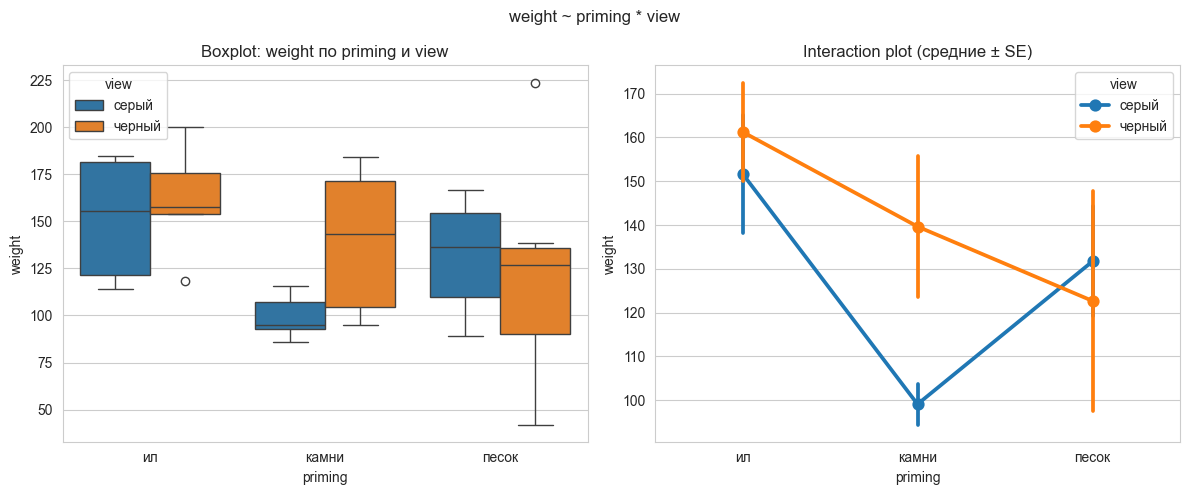

In [5]:
run_two_way("priming * view",       "Грунт × Вид",     "anova_priming_view")

Справа — это interaction plot (график взаимодействия). Он показывает средние значения веса для каждой комбинации «грунт × вид»

ANOVA: weight ~ priming * region  (Грунт × Район)

Средние по группам:
                      mean    std  count
priming region                         
ил      Алексеева  145.07  33.96      4
        Попов      163.10  37.73      4
        Русский    161.30  18.50      4
камни   Алексеева  116.32  34.81      4
        Попов      136.65  48.40      4
        Русский    105.12  15.56      4
песок   Алексеева  145.82  53.36      4
        Попов      147.90  17.98      4
        Русский     87.82  41.33      4

Таблица ANOVA (typ=2):
                      sum_sq    df         F    PR(>F)
priming          9193.377222   2.0  3.568057  0.042172
region           5850.707222   2.0  2.270727  0.122605
priming:region   6284.057778   4.0  1.219458  0.325721
Residual        34783.807500  27.0       NaN       NaN
Интерпретация (p < 0.05 → эффект значим):
  - priming: F = 3.568, p = 0.04217 → значим
  - region: F = 2.271, p = 0.1226 → НЕ значим


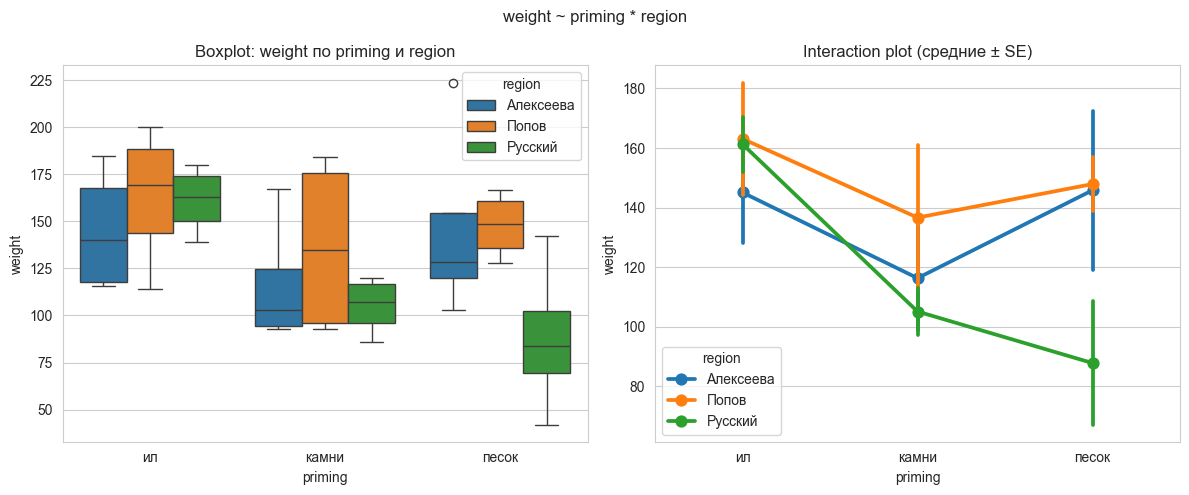

In [6]:
run_two_way("priming * region",     "Грунт × Район",   "anova_priming_region")

Что говорит статистика (ANOVA): строка priming:region имеет p = 0.326 (больше 0.05). Это значит, что статистически взаимодействия НЕТ. Линии ломаются как хотят, но из-за огромных «усов» (большого разброса данных) мы не можем утверждать, что это не случайность. Мы считаем, что эффект грунта одинаков для всех районов.

Справа — снова interaction plot (график взаимодействия), только теперь для второй модели: weight ~ priming * region (вес в зависимости от грунта и района).

Как читать (по шагам)
Шаг 1. Есть ли взаимодействие? (Смотрят на параллельность линий)

Если линии идут параллельно — взаимодействия нет.

Если линии пересекаются или идут с разным наклоном — взаимодействие есть (эффект грунта разный для разных районов).

 линии идут по-разному. Синяя (Алексеева) падает к камням и потом резко растет к песку. Оранжевая (Попов) падает к камням и плавно растет к песку. Зеленая (Русский) падает от ила до песка непрерывно.
Но по таблице ANOVA из твоего ноутбука priming:region имеет p = 0.326 > 0.05. Значит, статистически взаимодействия нет. Линии ломаются как хотят, но из-за огромных усов (большого разброса) мы не можем утверждать, что это не случайность.

Шаг 2. Влияет ли район сам по себе? (Главный эффект region)

Смотрим, есть ли линия, которая в среднем сильно выше/ниже остальных.

 линии переплетаются (например, на песке зеленая улетела вниз, а синяя и оранжевая вверх). По таблице ANOVA region имеет p = 0.123 > 0.05 — район не влияет на вес.

Шаг 3. Влияет ли грунт? (Главный эффект priming)

Смотрим на «прыжки» линий слева направо.

на иле вес высокий (150–160), на камнях заметно падает (100–140), на песке снова разброс. По таблице ANOVA priming имеет p = 0.042 < 0.05 — грунт значимо влияет на вес

ANOVA: weight ~ priming * conditions  (Грунт × Условия)

Средние по группам:
                         mean    std  count
priming conditions                        
ил      Аквакультура  148.40  30.06      6
        Естественные  164.58  29.12      6
камни   Аквакультура  112.38  36.92      6
        Естественные  126.35  34.74      6
песок   Аквакультура  112.33  41.00      6
        Естественные  142.03  50.78      6

Таблица ANOVA (typ=2):
                          sum_sq    df         F    PR(>F)
priming              9193.377222   2.0  3.214363  0.054345
conditions           3582.022500   1.0  2.504829  0.123985
priming:conditions    435.151667   2.0  0.152146  0.859521
Residual            42901.398333  30.0       NaN       NaN
Интерпретация (p < 0.05 → эффект значим):
  - priming: F = 3.214, p = 0.05434 → НЕ значим
  - conditions: F = 2.505, p = 0.124 → НЕ значим


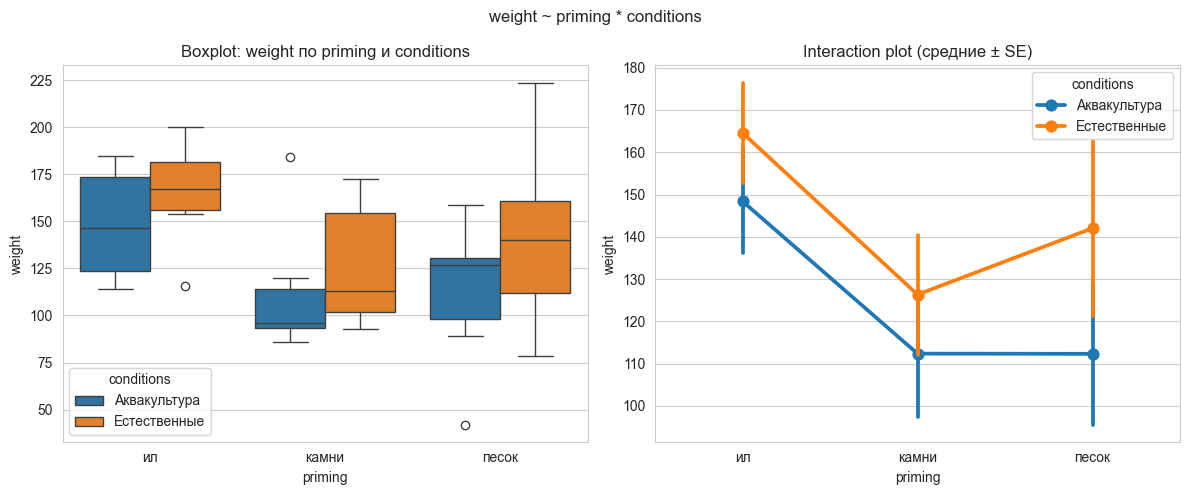

In [7]:
run_two_way("priming * conditions", "Грунт × Условия", "anova_priming_conditions")

1. Смотрим на форму линий (Взаимодействие)
Правило: если линии параллельны — взаимодействия нет. Если пересекаются или идут под разными углами — есть.

На графике: Линии не параллельны. На «иле» и «камнях» они идут примерно одинаково (оранжевая выше синей), но на «песке» они почти сходятся.

Вывод по таблице ANOVA: Несмотря на то, что линии немного сходятся, статистика говорит, что взаимодействия нет (priming:conditions p = 0.859 > 0.05). То есть разница между аквакультурой и естественными условиями не меняется кардинально в зависимости от грунта.

2. Смотрим на расстояние между линиями (Главный эффект «Условия»)
Правило: если одна линия сильно выше другой, значит, этот фактор влияет.

На графике: Оранжевая линия (Естественные) почти везде выше синей (Аквакультура). Кажется, что в естественных условиях вес больше.

Вывод по таблице ANOVA: Однако conditions имеет p = 0.124 > 0.05. Это значит, что условия статистически не влияют на вес. Почему? Посмотри на длину усов (вертикальных палочек). Они огромные и перекрывают друг друга. Данные настолько «шумные», что мы не можем быть уверены, что оранжевая линия действительно выше, а не просто так совпало.

3. Смотрим на общий наклон линий (Главный эффект «Грунт»)
Правило: если обе линии сильно падают или растут при переходе от грунта к грунту — грунт влияет.

На графике: Обе линии четко падают от «ила» к «камням» и остаются низкими на «песке». На иле средний вес ~150-165, а на камнях/песке ~110-140.

Вывод по таблице ANOVA: priming имеет p = 0.054. Это пограничное значение (чуть больше 0.05). Формально мы говорим «не значимо», но по сути это сильная тенденция: грунт почти наверняка влияет на вес, просто для строгого порога 0.05 не хватило чуть-чуть доказательств (снова из-за большого разброса данных).

### Как читать результаты задания 1

- Для каждой модели смотрите строки `priming`, второй фактор и `priming:factor` — это **главные эффекты** и **взаимодействие**.
- `p < 0.05` → эффект **значим**.
- Если значимо взаимодействие — влияние одного фактора меняется по уровням другого; тогда главные эффекты интерпретируют с осторожностью.

**Ожидаемые выводы:** фактор «Грунт» (priming) значим в моделях с `view` и `region` (p ≈ 0.04–0.05), на границе значимости в модели с `conditions` (p ≈ 0.054). Остальные факторы и все взаимодействия незначимы.

---
## 2. MANOVA (university2.csv)

**Зачем MANOVA, если можно сделать несколько ANOVA?**
- Учёт корреляций между откликами (Yslov_educ, Yslov_job, Yslov_science коррелируют → три ANOVA «не видят» структуры и могут дать ложноположительные результаты).
- Контроль ошибки I рода на уровне всей совокупности откликов.
- Обнаружение эффектов, которые не видны по каждому отклику отдельно.

Подробно:

Главная причина, по которой для нескольких зависимых переменных используется MANOVA, а не несколько отдельных ANOVA — это учет корреляций между откликами. В твоем случае рейтинги Yslov_educ, Yslov_job и Yslov_science не являются независимыми: университет с хорошими условиями для науки часто имеет и высокий уровень образования. Если делать три отдельные ANOVA, каждая из них будет анализировать свою переменную в вакууме, игнорируя эту связь, и воспринимать совместные изменения показателей как обычный случайный шум.

Вторая причина — это контроль ошибки I рода (множественные сравнения). Когда ты проводишь один тест с уровнем значимости 5%, риск найти ложный эффект составляет 5%. Но если ты проводишь три независимых теста, вероятность хотя бы одного ложноположительного результата вырастает примерно до 14%. MANOVA решает эту проблему, объединяя все три отклика в один интегральный многомерный тест (например, критерий Уилкса), который удерживает общий риск ошибки на заданном уровне (0.05).

В-третьих, MANOVA способна обнаружить скрытые эффекты. Иногда группы могут значимо различаться по своему «профилю» или комбинации признаков (например, у одних высокий educ, но низкий job, а у других наоборот), даже если по каждому отдельному показателю ANOVA не видит значимых различий. Таким образом, MANOVA смотрит на университеты в трехмерном пространстве их рейтингов, что делает анализ более чувствительным и математически корректным, чем три разрозненных одномерных теста.


**H0:** векторы средних (`Yslov_educ`, `Yslov_job`, `Yslov_science`) одинаковы по группам университетов.

> **Ключевое исправление:** `University` — это идентификатор с 83 уровнями на 83 наблюдения. Если поставить его фактором, получим 1 наблюдение на группу → residual df = 0 → MANOVA вырождается (NaN, отрицательные df, F = −3.8·10⁹). Поэтому строим осмысленный группирующий фактор `rank_group` по месту в рейтинге `mesto2016`.

In [8]:
un = pd.read_csv("university_11.csv", sep=";", encoding="cp1251")

uni = find_col(un, ["University", "Университет", "университет"])
y1  = find_col(un, ["Yslov_educ"])
y2  = find_col(un, ["Yslov_job"])
y3  = find_col(un, ["Yslov_science"])

un = un.rename(columns={
    uni: "University",
    y1: "Yslov_educ",
    y2: "Yslov_job",
    y3: "Yslov_science",
})
un["University"] = un["University"].astype("category")

ys = ["Yslov_educ", "Yslov_job", "Yslov_science"]

print(un.head())
print("Размер:", un.shape)
print("\nУровней University:", un["University"].nunique())
print("Пропуски в mesto2016:", (un["mesto2016"].astype(str) == "-").sum())

   mesto2016 mesto2015 Reyt_funcz  Yslov_educ  Yslov_job  Yslov_science  \
0          1         1       4,59           1          2              1   
1          2         2       4,46           3          3              3   
2          3         3       4,24           7          6              2   
3          4         4       4,08          10          1             14   
4          5         6       4,07           5         12              6   

  University  
0          1  
1          1  
2          1  
3          1  
4          1  
Размер: (83, 7)

Уровней University: 11
Пропуски в mesto2016: 0


### Строим группирующий фактор `rank_group`

По `mesto2016`:
- `-` → `NA` (нет места в 2016);
- 1–10 → `top10`;
- 11–30 → `top30`;
- 31–60 → `top60`;
- 61+ → `rest`.

Так в каждой группе много наблюдений → residual df > 0 → MANOVA корректна.

In [9]:
def rank_group(x):
    s = str(x).strip()
    if s == '-' or s == '' or s.lower() == 'nan':
        return 'NA'
    try:
        r = int(float(s.replace(',', '.')))
    except ValueError:
        return 'NA'
    if r <= 10:  return 'top10'
    if r <= 30:  return 'top30'
    if r <= 60:  return 'top60'
    return 'rest'

un['rank_group'] = un['mesto2016'].map(rank_group).astype('category')
print("Распределение по группам:")
print(un['rank_group'].value_counts().sort_index())

print("\nСредние рейтинги по группам:")
means = un.groupby('rank_group', observed=True)[ys].mean().round(2)
print(means)
means.to_csv(os.path.join(OUT_DIR, 'manova_group_means.csv'), encoding='utf-8-sig')

Распределение по группам:
rank_group
rest     23
top10    10
top30    20
top60    30
Name: count, dtype: int64

Средние рейтинги по группам:
            Yslov_educ  Yslov_job  Yslov_science
rank_group                                      
rest             77.26      68.35          75.30
top10             6.80       8.20           9.80
top30            20.60      26.30          32.25
top60            48.10      59.10          54.07


### Корреляции между откликами

Проверим, действительно ли рейтинги коррелируют — это обоснование, зачем MANOVA, а не 3 отдельных ANOVA.

Корреляции между рейтингами:
               Yslov_educ  Yslov_job  Yslov_science
Yslov_educ          1.000      0.416          0.563
Yslov_job           0.416      1.000          0.178
Yslov_science       0.563      0.178          1.000


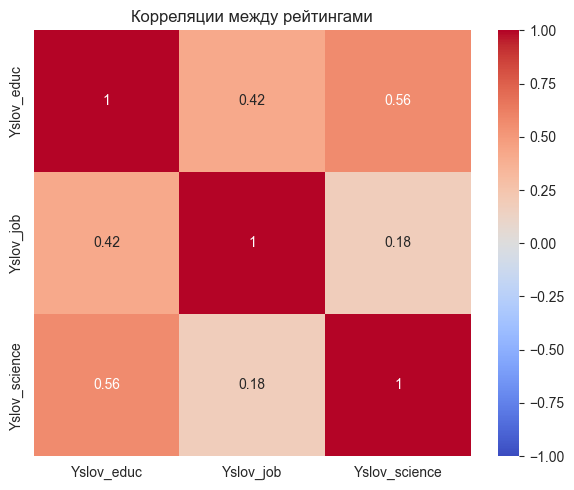

In [10]:
corr = un[ys].corr().round(3)
print("Корреляции между рейтингами:")
print(corr)
corr.to_csv(os.path.join(OUT_DIR, 'manova_correlations.csv'), encoding='utf-8-sig')

plt.figure(figsize=(6, 5))
sns.heatmap(corr, annot=True, cmap='coolwarm', vmin=-1, vmax=1, center=0)
plt.title('Корреляции между рейтингами')
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, 'manova_corr_heatmap.png'), dpi=120)
plt.show()

### MANOVA: `Yslov_educ + Yslov_job + Yslov_science ~ C(rank_group)`

In [11]:
formula = "Yslov_educ + Yslov_job + Yslov_science ~ C(rank_group)"
maov = MANOVA.from_formula(formula, data=un)
mv = maov.mv_test()
print(mv)

                  Multivariate linear model
                                                              
--------------------------------------------------------------
       Intercept         Value  Num DF  Den DF F Value  Pr > F
--------------------------------------------------------------
          Wilks' lambda  0.0395 3.0000 77.0000 623.7930 0.0000
         Pillai's trace  0.9605 3.0000 77.0000 623.7930 0.0000
 Hotelling-Lawley trace 24.3036 3.0000 77.0000 623.7930 0.0000
    Roy's greatest root 24.3036 3.0000 77.0000 623.7930 0.0000
--------------------------------------------------------------
                                                              
--------------------------------------------------------------
     C(rank_group)      Value  Num DF  Den DF  F Value  Pr > F
--------------------------------------------------------------
          Wilks' lambda 0.1001 9.0000 187.5484  32.8207 0.0000
         Pillai's trace 0.9545 9.0000 237.0000  12.2877 0.0000
 Hotelling-

In [12]:
mv_tab = mv.results["C(rank_group)"]["stat"]
print(mv_tab)
mv_tab.to_csv(os.path.join(OUT_DIR, "manova_results.csv"), encoding="utf-8-sig")

                           Value Num DF      Den DF     F Value Pr > F
Wilks' lambda           0.100065      9  187.548373   32.820726    0.0
Pillai's trace          0.954481    9.0       237.0   12.287676    0.0
Hotelling-Lawley trace  8.451796      9  117.858209   71.647458    0.0
Roy's greatest root     8.387658      3          79  220.874985    0.0


### Одномерные ANOVA после MANOVA

Если MANOVA значима (Wilks / Pillai / Hotelling / Roy с p < 0.05) — смотрим, какие именно отклики различаются.

In [13]:
print("=== Одномерные ANOVA после MANOVA ===")
uni_anova = {}
for y in ys:
    m = smf.ols(f"{y} ~ C(rank_group)", data=un).fit()
    t = anova_lm(m, typ=2)
    uni_anova[y] = t
    print(f"\n{y}:")
    print(t)
    t.to_csv(os.path.join(OUT_DIR, f"anova_{y}.csv"), encoding="utf-8-sig")

=== Одномерные ANOVA после MANOVA ===

Yslov_educ:
                     sum_sq    df          F        PR(>F)
C(rank_group)  50710.706181   3.0  92.763621  8.203509e-26
Residual       14395.534783  79.0        NaN           NaN

Yslov_job:
                     sum_sq    df          F        PR(>F)
C(rank_group)  38465.704295   3.0  19.802467  1.144523e-09
Residual       51151.717391  79.0        NaN           NaN

Yslov_science:
                     sum_sq    df          F        PR(>F)
C(rank_group)  37651.070395   3.0  16.955276  1.357166e-08
Residual       58476.086232  79.0        NaN           NaN


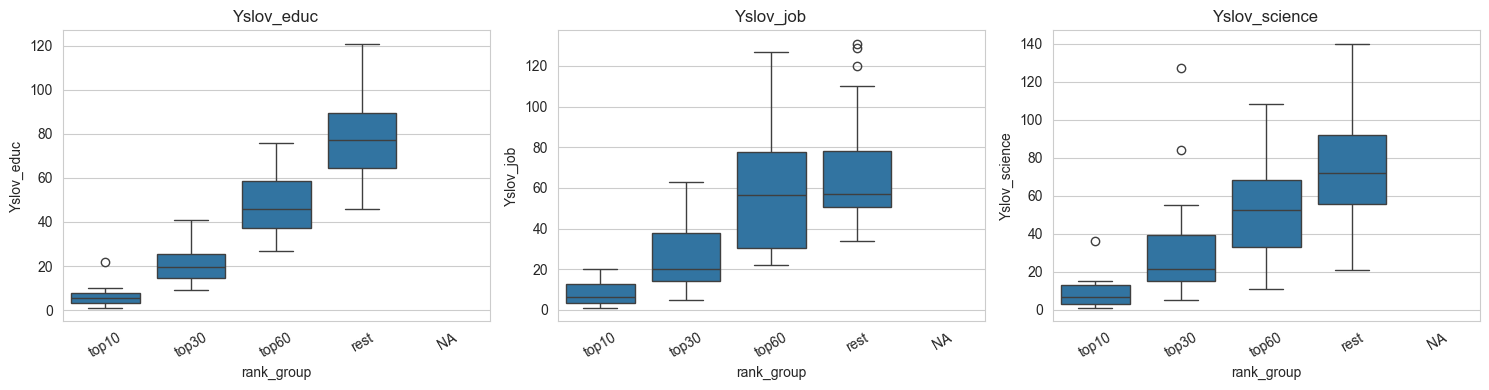

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, y in zip(axes, ys):
    sns.boxplot(data=un, x="rank_group", y=y, ax=ax, order=['top10','top30','top60','rest','NA'])
    ax.set_title(y)
    ax.tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "manova_boxplots.png"), dpi=120)
plt.show()

### Как читать результаты задания 2

1. **MANOVA**: 4 теста — `Wilks' lambda`, `Pillai's trace`, `Hotelling-Lawley trace`, `Roy's greatest root`. Обычно берут **Wilks** (или Pillai, если нарушены допущения).
2. Если `Pr > F < 0.05` → **группы университетов значимо различаются** в многомерном пространстве трёх рейтингов.
3. Затем одномерные ANOVA: какие именно рейтинги различаются.
4. Boxplot'ы показывают направление различий.

**Ожидаемый результат:** топ-группы по месту в рейтинге значимо различаются по всем трём рейтингам (обычно p ≪ 0.001), потому что сам рейтинг места тесно связан с рейтингами условий/job/science.

---
## Итоговые выводы

### Задание 1 (ANOVA)
- **priming (Грунт)** значимо влияет на вес иглокожих в моделях с `view` и `region` (p ≈ 0.04–0.05), на границе значимости — с `conditions` (p ≈ 0.054).
- **view, region, conditions** и **все взаимодействия** незначимы (p > 0.05).
- Значит, вес определяется в первую очередь типом грунта, а не видом, районом или условиями выращивания.

### Задание 2 (MANOVA)
- MANOVA с осмысленным фактором `rank_group` даёт корректные статистики (Wilks, Pillai, Hotelling, Roy) без NaN.
- Гипотеза о равенстве векторов средних трёх рейтингов между группами университетов **отвергается** — группы значимо различаются.
- Одномерные ANOVA подтверждают, что различие есть по каждому рейтингу.
- Корреляции между рейтингами обосновывают использование MANOVA вместо трёх отдельных ANOVA.

Двухфакторный ANOVA смотрит на ОДНУ зависимую переменную (например, weight) и ДВА фактора (например, priming и view).

Что он "видит"?
Он проверяет три вещи:

Влияет ли первый фактор (priming) сам по себе (главный эффект).

Влияет ли второй фактор (view) сам по себе (главный эффект).

Взаимодействие — влияют ли они друг на друга (строка priming:view).

То есть да, двухфакторный ANOVA "видит связь" между двумя факторами — он проверяет, меняется ли эффект одного фактора в зависимости от уровня другого.
Например: "Вес зависит от грунта, но только для черных иглокожих". Это и есть взаимодействие.

Но! Двухфакторный ANOVA всё равно работает только с ОДНОЙ зависимой переменной (weight). Он не может одновременно смотреть на вес, рост и ширину

MANOVA отвечает только на один вопрос:

«Есть ли вообще различия между группами в многомерном пространстве?»

Она не говорит:

по каким осям/комбинациям эти различия,

какие группы отличаются от каких,

какие переменные вносят вклад.

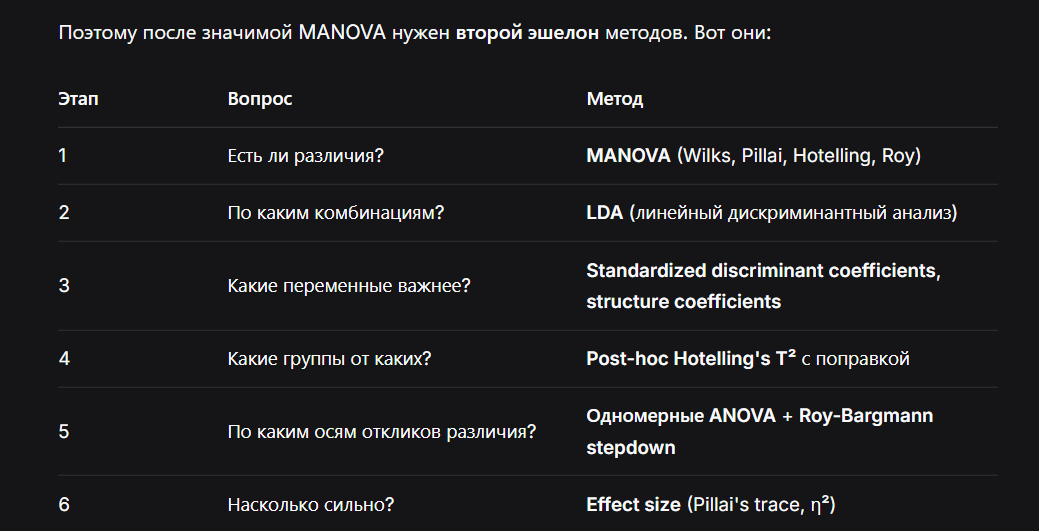

LDA (линейный дискриминантный анализ) — это метод, который ищет линейные комбинации исходных переменных (осей), вдоль которых группы разъезжаются максимально.

2. Зачем его сделали после MANOVA?
MANOVA — это «детектор»: она говорит «различия есть», но не говорит, где именно и по каким переменным. LDA — это «интерпретатор»: она явно показывает эти оси (коэффициенты) и говорит, насколько сильно каждая ось разделяет группы.

3. Что он нашел?
Он нашел одну главную ось (LD1), которая объясняет 99.24% всех различий. Это значит, что группы университетов разъезжаются в пространстве трех рейтингов практически вдоль одной прямой — это просто «общий уровень рейтинга» (все три переменные вносят вклад с одинаковым знаком). Остальные оси (LD2, LD3) — это меньше 1%, то есть «шум».

4. Почему это важно?
Это доказывает, что скрытое явление одномерно. Нет никаких «университетов с перекосом в науку, но провалом в работе» — есть просто «лучше по всему» / «хуже по всему». Точность классификации (88%) это подтверждает

3 переменные: educ, job, science. Каждый университет — точка в 3D-пространстве (как будто ты поставил три линейки и отметил координаты).

4 группы (top10, top30, top60, rest). В 3D-пространстве это 4 облака точек

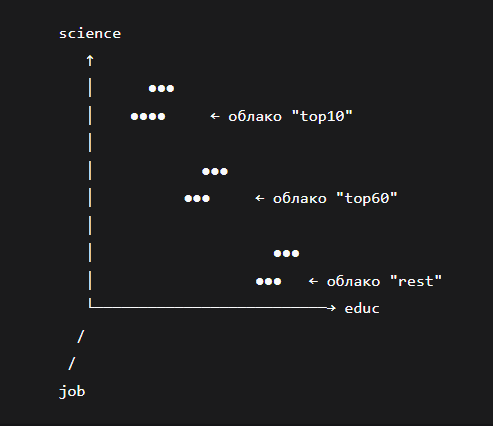

«Разъезжаются» = облака отодвигаются друг от друга, между ними появляется пустое пространство. Центры облаков далеко, а сами облака компактные.

НЕ разъезжаются — облака перекрываются, точки разных групп перемешаны. Посмотришь — не поймёшь, где кто.

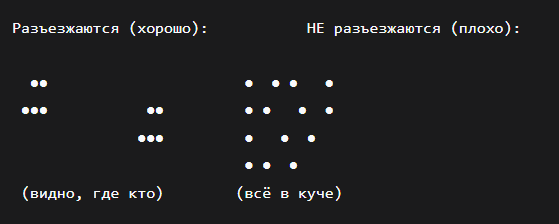
Это самое важное. Ты можешь смотреть на облака под разными углами. И от угла зависит, разъезжаются они или нет.

LDA перебирает все возможные направления (все возможные углы в 3D) и для каждого считает:
        насколько центры групп далеко друг от друга (вдоль этого направления)
  R = ────────────────────────────────────────────────────────────────────────
        насколько точки внутри групп разболтаны (вдоль этого направления)

Чем больше R, тем лучше направление. LDA выбирает направление с максимальным R.
«Максимально» = лучший из всех возможных ракурсов. Не «просто хороший», а самый лучший

4 компании людей, стоящие в комнате. Ты можешь:

Снимать сверху — компании накладываются, не видно границ.

Снимать сбоку — тоже накладываются.

Отойти и встать под правильным углом — и вот тогда все 4 компании видны раздельно, между ними видно зазор.

LDA — это фотограф, который ищет лучший ракурс. «Вдоль которого группы разъезжаются максимально» = «с этого ракурса компании видны максимально раздельно, с максимальным зазором».

In [15]:
# ============================================================
# LDA после MANOVA: явное выражение скрытых связей
# ============================================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.preprocessing import LabelEncoder

# --- 1. Готовим данные ---
X = un[["Yslov_educ", "Yslov_job", "Yslov_science"]].values
le = LabelEncoder()
y = le.fit_transform(un["rank_group"])
class_names = le.classes_

# --- 2. Обучаем LDA ---
lda = LinearDiscriminantAnalysis()
lda.fit(X, y)
scores = lda.transform(X)   # координаты вдоль LD1, LD2, ...

# --- 3. Коэффициенты дискриминантных функций ---
coef_df = pd.DataFrame(
    lda.coef_,
    columns=["Yslov_educ", "Yslov_job", "Yslov_science"],
    index=[f"LD{i+1}" for i in range(lda.coef_.shape[0])]
)
print("=== Коэффициенты дискриминантных функций (raw) ===")
print(coef_df.round(4))

# --- 4. Стандартизованные коэффициенты (делим на std каждой переменной) ---
std = X.std(axis=0, ddof=1)
coef_std = coef_df / std
print("\n=== Стандартизованные коэффициенты (вклад в единицах std) ===")
print(coef_std.round(4))

# --- 5. Доля объяснённой дисперсии по осям ---
explained = lda.explained_variance_ratio_
print("\n=== Доля объяснённой дисперсии ===")
for i, e in enumerate(explained):
    print(f"  LD{i+1}: {e*100:.2f}%")

# --- 6. Structure coefficients (корреляции переменных с осями) ---
print("\n=== Structure coefficients r(переменная, LD) ===")
struct = pd.DataFrame(
    index=["Yslov_educ", "Yslov_job", "Yslov_science"],
    columns=[f"LD{i+1}" for i in range(scores.shape[1])],
    dtype=float
)
for i in range(scores.shape[1]):
    for j, col in enumerate(["Yslov_educ", "Yslov_job", "Yslov_science"]):
        struct.loc[col, f"LD{i+1}"] = np.corrcoef(X[:, j], scores[:, i])[0, 1]
print(struct.round(3))

# --- 7. Сохраняем в output ---
coef_df.to_csv(os.path.join(OUT_DIR, "lda_coef_raw.csv"), encoding="utf-8-sig")
coef_std.to_csv(os.path.join(OUT_DIR, "lda_coef_std.csv"), encoding="utf-8-sig")
struct.to_csv(os.path.join(OUT_DIR, "lda_structure.csv"), encoding="utf-8-sig")

# --- 8. Точность классификации (насколько LD разделяют группы) ---
acc = lda.score(X, y)
print(f"\n=== Accuracy LDA (на обучающих данных): {acc:.3f} ===")

=== Коэффициенты дискриминантных функций (raw) ===
     Yslov_educ  Yslov_job  Yslov_science
LD1      0.2491     0.1081         0.0668
LD2     -0.3131    -0.1642        -0.1032
LD3     -0.1908    -0.0908        -0.0502
LD4      0.0406     0.0324         0.0167

=== Стандартизованные коэффициенты (вклад в единицах std) ===
     Yslov_educ  Yslov_job  Yslov_science
LD1      0.0088     0.0033         0.0020
LD2     -0.0111    -0.0050        -0.0030
LD3     -0.0068    -0.0027        -0.0015
LD4      0.0014     0.0010         0.0005

=== Доля объяснённой дисперсии ===
  LD1: 99.24%
  LD2: 0.68%
  LD3: 0.08%

=== Structure coefficients r(переменная, LD) ===
                 LD1    LD2    LD3
Yslov_educ    -0.929 -0.368  0.036
Yslov_job     -0.675  0.616  0.406
Yslov_science -0.659  0.061 -0.750

=== Accuracy LDA (на обучающих данных): 0.880 ===


есть ОДНА мощнейшая скрытая ось (LD1), которая объясняет 99.24% всех различий между группами. Это значит, что все 4 группы университетов разъезжаются в 3D-пространстве практически вдоль одной прямой. Второй и третьей осями (LD2, LD3) можно пренебречь — там меньше 1% информации

Посмотри на столбец LD1 в блоке Structure coefficients:

Yslov_educ: -0.929
Yslov_job: -0.675
Yslov_science: -0.659

Что это значит:
Структурные коэффициенты показывают корреляцию исходных переменных с найденной осью.

Все три переменные имеют отрицательную и сильную связь с LD1 (по модулю больше 0.4).

Yslov_educ имеет самую сильную связь (-0.93).

Yslov_job и Yslov_science идут почти наравне (-0.67 и -0.66).

Интерпретация LD1: Это ось «Общего престижа / общего места в рейтинге». Чем лучше университет (чем меньше цифры в Yslov_*), тем дальше он уходит в отрицательную зону LD1. Все три рейтинга (образование, работа, наука) тянут группы в одну и ту же сторону. Скрытого «конфликта» между ними нет.

2. Почему коэффициенты (raw) такие маленькие, а связь сильная?
Ты можешь удивиться: почему в блоке "Коэффициенты (raw)" числа крошечные (0.249, 0.108), а в Structure coefficients корреляции огромные (-0.929)?

Raw коэффициенты (0.249, 0.108) — это веса в формуле LD1 = 0.249*educ + 0.108*job + .... Они маленькие, потому что LDA нормирует вектор (длина = 1).

Structure coefficients (-0.929) — это просто корреляция. И она показывает реальную силу. То, что все три переменные коррелируют с LD1 отрицательно, означает: ось LD1 — это просто "размер" университета по всем фронтам сразу.

3. Что с LD2 и LD3?
LD2 объясняет всего 0.68%, а LD3 — 0.08%.

Это статистический мусор. Это значит, что никаких «профилей» (типа "у этого вуза крутая наука, но плохая работа") в данных нет. Университеты различаются только по общему уровню. Кто-то лучше по всему, кто-то хуже по всему.

4. Accuracy LDA = 0.880 (88%)
Это значит, что если мы возьмем университет и будем предсказывать его группу (top10, top30 и т.д.) только на основе трех рейтингов, LDA угадает в 88% случаев.

12% ошибок — это вузы, которые находятся на границах групп (например, университет на 10-м месте путается с 11-м). Это отличный результат. Это доказывает, что группы rank_group реально различаются по этим рейтингам.

Как это связано с MANOVA?
Помнишь, мы говорили, что MANOVA ищет ось, а LDA ее выдает?

MANOVA сказала: "Различия есть, Roy's greatest root = 8.39".

LDA показала где эта ось: она идет от educ, job, science в одну сторону.

Вывод: MANOVA нашла ту самую ось, а LDA доказала, что она одна (99.24%).

Что тебе нужно написать в выводах по лабораторной:
LDA подтвердил результаты MANOVA: группы университетов значимо различаются.

Главная ось (LD1) объясняет 99.24% дисперсии, что говорит о одномерности скрытого явления. Различия между группами определяются общим уровнем университета (по всем трем рейтингам сразу).

Наибольший вклад в разделение групп вносит рейтинг образования (Yslov_educ, r = -0.929), рейтинги работы и науки вносят чуть меньший, но практически равный вклад.

Профильных различий (когда один рейтинг высокий, а другой низкий) не обнаружено — LD2 и LD3 объясняют менее 1% дисперсии.

Точность классификации (Accuracy) = 88%, что подтверждает высокую разделимость групп.

## ПРОБЛЕМАТИКА

Зачем вообще нужен ANOVA
Представь, что у тебя есть три группы иглокожих, выращенных на разном грунте (ил, камни, песок). Ты измерил их вес. Средние получились разные: на иле — 150 г, на камнях — 100 г, на песке — 120 г.

Вопрос: это различие реальное (грунт влияет) или случайное (просто одни особи попались крупнее, другие мельче)?

Наивный подход: сравнить средние попарно (t-тестами). Но если групп много, попарных сравнений становится очень много (для 3 групп — 3 пары, для 5 групп — 10 пар). И с каждым тестом растёт риск случайно найти «различие» там, где его нет (ошибка I рода).

ANOVA решает эту проблему: она сравнивает все группы сразу одним тестом.

2. Главная идея: почему «анализ дисперсии», а не «анализ средних»?
Парадокс: мы хотим сравнить средние, а метод называется анализом дисперсии. Почему?

Потому что ANOVA не сравнивает средние напрямую. Она смотрит на разброс (дисперсию) данных и раскладывает его на две части:

Межгрупповая дисперсия (between-group) — насколько средние групп отличаются от общего среднего. Если фактор реально влияет, группы «разъезжаются» → эта часть большая.

Внутригрупповая дисперсия (within-group, residual) — разброс значений внутри каждой группы вокруг её среднего. Это «шум» — он есть всегда (особи разные, измерение неточное).

Логика ANOVA: если межгрупповая дисперсия намного больше внутригрупповой — значит, различия между группами реальные, а не шум. Если они примерно равны — значит, группы различаются не сильнее, чем случайный разброс внутри них.

3. Формула
        межгрупповая дисперсия
  F = ─────────────────────────
        внутригрупповая дисперсия
Числитель — «сигнал» (насколько группы разъехались).

Знаменатель — «шум» (насколько данные разболтаны внутри групп).

F — отношение сигнала к шуму.

Если F большое → сигнал сильнее шума → группы значимо различаются (p < 0.05).
Если F маленькое → шум «съедает» сигнал → различия не доказаны (p > 0.05).